# Logistic Regression Titanic Survival Prediction Project

## 1. Problem Statement

The objective is to predict whether a passenger survived
the Titanic disaster using passenger-related features.


In [29]:
# important libraries
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt

In [30]:
# Data loading

df = pd.read_csv("train.csv")

In [4]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [31]:
# feature Selection

X = df[
    [
        "Pclass",
        "Sex",
        "Age",
        "SibSp",
        "Parch",
        "Fare",
        "Embarked"
    ]
    ]

y = df["Survived"]

In [32]:
# Spliting the data for training and testing
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [7]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(712, 7)
(179, 7)
(712,)
(179,)


In [33]:
# sklearn libraries
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Numerical columns
numerical_transformer = SimpleImputer(strategy="median")

# Sex Column
sex_transformer = OneHotEncoder(handle_unknown="ignore")

# Embarked column: imputation + encoding
embarked_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# combine all transformations

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, ["Age", "Fare"]),
        ("sex", sex_transformer, ["Sex"]),
        ("embarked", embarked_transformer, ["Embarked"])
    ],
    remainder="passthrough"
)

# model pipeline
model_pipeline = Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42))
    ]
)

# Train the complete pipeline
model_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['Pclass','Sex','Age',...,'Parch','Fare','Embarked']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('sex', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining c

In [34]:
# model evaluation

y_pred = model_pipeline.predict(X_test)
print(y_pred[:10])

[0 0 0 0 1 0 1 0 0 0]


In [10]:
feature_names = preprocessor.get_feature_names_out()

print("Total features:", len(feature_names))
print("\n Feature names: ")

for feature in feature_names:
    print(feature)

Total features: 10

 Feature names: 
num__Age
num__Fare
sex__Sex_female
sex__Sex_male
embarked__Embarked_C
embarked__Embarked_Q
embarked__Embarked_S
remainder__Pclass
remainder__SibSp
remainder__Parch


In [12]:
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score, precision_score, f1_score
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("accuracy score: ",accuracy*100 ,"%")
print("confusion matrix: ",cm)
print("recall score: ", recall)
print("precision score: ", precision)
print("f1_score: ", f1)

accuracy score:  80.44692737430168 %
confusion matrix:  [[98 12]
 [23 46]]
recall score:  0.6666666666666666
precision score:  0.7931034482758621
f1_score:  0.7244094488188977


In [14]:
from sklearn.metrics import roc_auc_score, roc_curve

probabilities = model_pipeline.predict_proba(X_test)[:, 1]
print(probabilities)

roc_score = roc_auc_score(y_test, probabilities)
print(roc_score)

[0.06814432 0.04764328 0.1556849  0.03556917 0.67189281 0.4426485
 0.7520414  0.32534576 0.34497265 0.16090383 0.15833804 0.08969662
 0.58614297 0.23088701 0.47460239 0.17736795 0.37813571 0.08874169
 0.13204249 0.76628685 0.08874169 0.77679948 0.08412733 0.43413155
 0.08714811 0.96041422 0.15833804 0.26137252 0.12325291 0.12696486
 0.0728704  0.94880104 0.09493925 0.10032719 0.13234027 0.15497865
 0.15427255 0.36811975 0.15833804 0.83906217 0.12629207 0.96868465
 0.12163574 0.86346712 0.76243729 0.11535984 0.08899989 0.40042059
 0.7695432  0.88090284 0.92337305 0.57196399 0.72072353 0.22843153
 0.73042378 0.09694138 0.07175771 0.4157544  0.64135172 0.42539047
 0.60880602 0.70069429 0.13674133 0.13348276 0.40964685 0.55568998
 0.94230982 0.07577018 0.20749673 0.26079496 0.74129488 0.12521212
 0.68754436 0.9589682  0.19874904 0.05010825 0.07028125 0.08003121
 0.15143749 0.54683638 0.07078038 0.11894891 0.14578353 0.09688845
 0.77566249 0.28075134 0.10594043 0.51473769 0.56088615 0.95111

In [15]:
roc_score = roc_auc_score(y_test, probabilities)
print(roc_score)

0.8437417654808959


In [16]:
fpr, tpr, thresholds = roc_curve(y_test, probabilities)

print("FPR: ",fpr)
print("TPR: ",tpr)
print("threshold: ", thresholds)

FPR:  [0.         0.00909091 0.00909091 0.01818182 0.01818182 0.02727273
 0.02727273 0.02727273 0.03636364 0.03636364 0.04545455 0.04545455
 0.04545455 0.06363636 0.06363636 0.08181818 0.08181818 0.09090909
 0.09090909 0.10909091 0.10909091 0.12727273 0.12727273 0.14545455
 0.14545455 0.15454545 0.15454545 0.21818182 0.21818182 0.27272727
 0.27272727 0.3        0.3        0.32727273 0.32727273 0.36363636
 0.38181818 0.42727273 0.49090909 0.5        0.5        0.56363636
 0.56363636 0.6        0.61818182 0.62727273 0.62727273 0.7
 0.7        0.73636364 0.73636364 0.78181818 0.78181818 0.8
 0.82727273 0.89090909 0.89090909 0.91818182 0.93636364 1.        ]
TPR:  [0.         0.         0.26086957 0.26086957 0.33333333 0.33333333
 0.46376812 0.49275362 0.49275362 0.50724638 0.50724638 0.53623188
 0.57971014 0.57971014 0.62318841 0.62318841 0.63768116 0.63768116
 0.65217391 0.65217391 0.69565217 0.69565217 0.71014493 0.71014493
 0.73913043 0.73913043 0.7826087  0.7826087  0.79710145 0.79710

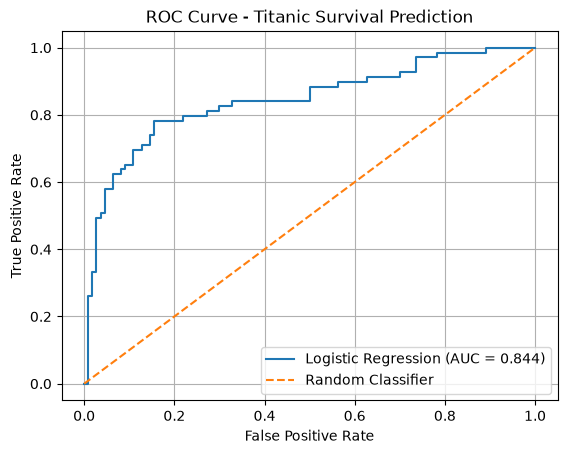

In [17]:
import matplotlib.pyplot as plt

plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_score:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Titanic Survival Prediction")

plt.legend()
plt.grid(True)

plt.show()

In [18]:
test = pd.read_csv("test.csv")

In [19]:
test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [20]:
test.shape

(418, 11)

In [21]:
test.columns

Index(['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch',
       'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

In [23]:
X_kaggle_final = test[
        [
        "Pclass",
        "Sex",
        "Age",
        "SibSp",
        "Parch",
        "Fare",
        "Embarked"
    ]
    ]

In [24]:
X_kaggle_final.shape

(418, 7)

In [26]:
test_predictions = model_pipeline.predict(X_kaggle_final)
print(test_predictions)

[0 0 0 0 1 0 1 0 1 0 0 0 1 0 1 1 0 0 1 1 0 0 1 1 1 0 1 0 0 0 0 0 0 0 1 0 1
 1 0 0 0 0 0 1 1 0 0 0 1 0 0 0 1 1 0 0 0 0 0 1 0 0 0 1 1 1 1 0 1 1 1 0 1 1
 1 1 0 1 0 1 0 0 0 0 0 0 1 1 1 0 1 0 1 0 1 0 1 0 1 0 1 0 0 0 1 0 0 0 0 0 0
 1 1 1 1 0 0 1 1 1 1 0 1 0 0 1 0 1 0 0 0 0 1 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0
 0 0 1 0 0 0 0 0 1 1 0 1 1 0 1 0 0 1 0 0 1 1 0 0 0 0 0 1 1 0 1 1 0 0 1 0 1
 0 1 0 0 0 0 0 0 0 0 0 1 1 0 1 1 0 0 1 0 1 1 0 1 0 0 0 0 0 0 0 1 0 1 0 1 0
 1 0 1 1 0 1 0 0 0 1 0 0 0 0 0 0 1 1 1 1 0 0 0 0 1 0 1 1 1 0 1 0 0 0 0 0 1
 0 0 0 1 1 0 0 0 0 1 0 0 0 1 1 0 1 0 0 0 0 1 0 1 1 1 0 0 0 0 0 0 1 0 0 0 0
 1 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 1 1 1 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 0 0
 1 0 0 0 0 0 0 0 0 0 1 0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 0 0 1 1 0 1 0 0 1 1 0
 0 1 0 0 1 1 1 0 0 0 0 0 1 1 0 1 0 0 0 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 0 0 0
 0 1 1 1 1 1 0 1 0 0 0]


In [27]:
print(len(test_predictions))

418


In [29]:
np.unique(test_predictions)

array([0, 1])

In [30]:
submission = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": test_predictions
})

In [31]:
submission.head()

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


In [32]:
submission.shape

(418, 2)

In [33]:
submission.columns

Index(['PassengerId', 'Survived'], dtype='str')

In [34]:
submission.to_csv("submission.csv", index=False)